# Growth Sequential — Kernel, Constrained (Uno)

## Setup

[JAX](https://docs.jax.dev) underlies everything below: array math via
`jax.numpy`,
[compilation](https://docs.jax.dev/en/latest/jit-compilation.html) via
`jax.jit`, and exact derivatives via [automatic
differentiation](https://docs.jax.dev/en/latest/automatic-differentiation.html)
— the solver differentiates the residual program itself, so no
derivative is coded by hand. JAX defaults to 32-bit floats, so we switch
on 64-bit and the most accurate matmul *before* creating any array, then
import everything we need.

This notebook solves the same problem as the companion ridgeless
notebook, but with a **constrained optimizer**: the interior-point
solver [Uno](https://github.com/cvanaret/Uno) through `unopy`, with JAX
supplying the gradient, Jacobian, and Hessian callbacks. The model code
— `p`, the kernel matrices, `residual_fn`, and the warm-started
`theta_0` — is the ridgeless notebook’s, retyped verbatim; here `p` is
only a value container, since the NLP solver is host-side C++ and
nothing differentiates through it.

In [1]:
import jax

jax.config.update("jax_enable_x64", True)
jax.config.update("jax_default_matmul_precision", "highest")

import math
import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import unopy
from jax.flatten_util import ravel_pytree

Structural parameters: the Aruoba–Fernández-Villaverde–Rubio-Ramírez
calibration, with the continuous discount rate mapped from the quarterly
anchor $e^{-\hat\rho/4} = \beta$.

In [2]:
a = 1.0 / 3.0  # capital share in f(k) = k^a
delta = 0.1  # depreciation rate
rho_hat = -4.0 * math.log(0.9896)  # continuous discount rate (quarterly beta anchor)
sigma_crra = 2.0  # CRRA curvature
k_0 = 1.0  # initial capital
p = {"a": a, "delta": delta, "rho_hat": rho_hat, "sigma_crra": sigma_crra, "k_0": k_0}

Parameters of the algorithm: the kernel hyperparameters and the
collocation and test grids.

In [3]:
ELL = 10.0  # Matern-1/2 length scale
SIGMA = 1.0  # kernel amplitude
TRAIN_T = 100.0
N_TRAIN = 401
TEST_T = 110.0
N_TEST = 100
N_VALIDATION = 801  # twice the node density, so it samples between nodes
TVC_T = 200.0
TRAIN_RESIDUAL = 1e-5
VALIDATION_RESIDUAL = 2e-4

t_train = jnp.linspace(0.0, TRAIN_T, N_TRAIN)
t_test = jnp.linspace(0.0, TEST_T, N_TEST)
t_validation = jnp.linspace(0.0, TRAIN_T, N_VALIDATION)

## The model

The planner problem and its Pontryagin conditions are exactly those of
the ridgeless notebook: with costate $\mu$,

$$
k'(t) = k(t)^a - \delta k(t) - c(t),
\qquad
\mu'(t) = -\mu(t)\big(a\, k(t)^{a-1} - \delta - \hat\rho\big),
\qquad
\mu(t) = c(t)^{-\sigma},
$$

with $k(0) = k_0$ pinned, $(c_0, \mu_0)$ free, no terminal condition,
and transversality verified after the fact. Each of the three paths
$(\mu, c, k)$ is an integrated Matérn-1/2 expansion

$$
x(t) = x(0) + \sum_j \alpha_j \tilde K(t, t_j),
\qquad
x'(t) = \sum_j \alpha_j k(t, t_j),
$$

with $k(t, t') = \sigma^2 e^{-|t-t'|/\ell}$,
$h(d) = \sigma^2 \ell (1 - e^{-d/\ell})$, and
$\tilde K(t_i, t_j) = h(t_j) + \operatorname{sign}(t_i - t_j) h(|t_i - t_j|)$.
Stacked on the training grid, the three Pontryagin residuals give the
same `residual_fn` as the ridgeless notebook, $1/\sqrt{3n}$ scaling
included.

In [4]:
def antiderivative(d):
    return SIGMA**2 * ELL * (1.0 - jnp.exp(-d / ELL))


def kernel_matrices(t_i, t_j):
    s = t_i[:, None] - t_j[None, :]
    K = SIGMA**2 * jnp.exp(-jnp.abs(s) / ELL)
    K_tilde = antiderivative(t_j)[None, :] + jnp.sign(s) * antiderivative(jnp.abs(s))
    return K, K_tilde


def residual_fn(theta, args, p):
    K, K_tilde = args["K"], args["K_tilde"]
    mu = theta["mu_0"] + K_tilde @ theta["alpha_mu"]
    dmu_dt = K @ theta["alpha_mu"]
    c = theta["c_0"] + K_tilde @ theta["alpha_c"]
    k = p["k_0"] + K_tilde @ theta["alpha_k"]
    dk_dt = K @ theta["alpha_k"]
    resource = dk_dt - (k ** p["a"] - p["delta"] * k - c)
    euler = dmu_dt + mu * (p["a"] * k ** (p["a"] - 1.0) - p["delta"] - p["rho_hat"])
    shadow_price = mu * c ** p["sigma_crra"] - 1.0
    residual = jnp.concatenate([resource, euler, shadow_price])
    return residual / jnp.sqrt(residual.size)

## The constrained program

The ridgeless notebook reaches the minimum-norm interpolant as the
$\lambda \to 0$ limit of the penalized least squares. The
constrained-optimizer implementation solves that limit **exactly**, as
the nonlinear program

$$
\min_{\alpha_\mu, \alpha_c, \alpha_k,\, c_0, \mu_0}\
\alpha_\mu^\top K \alpha_\mu + \alpha_c^\top K \alpha_c + \alpha_k^\top K \alpha_k
\quad \text{s.t.} \quad
\begin{aligned}
&k' - \big(k^a - \delta k - c\big) = 0, \\
&\mu' + \mu\big(a k^{a-1} - \delta - \hat\rho\big) = 0, \\
&\mu c^\sigma - 1 = 0,
\end{aligned}
$$

at every training date. The equality constraints are `residual_fn`
verbatim — its constant $1/\sqrt{3n}$ scale is immaterial to the
constraint set — with `ravel_pytree` flattening the ridgeless `theta_0`
dict (sorted keys) into Uno’s flat vector and returning the inverse
`unravel`; the free scalars $(c_0, \mu_0)$ warm-start at the flat
steady-flow guess, exactly as in the ridgeless notebook. JAX supplies
`jax.grad`,
[`jax.jacfwd`](https://docs.jax.dev/en/latest/automatic-differentiation.html),
and the Lagrangian Hessian via `jax.hessian` as jitted callbacks.

In [5]:
K, K_tilde = kernel_matrices(t_train, t_train)
args = {"K": K, "K_tilde": K_tilde}

c_flow = k_0**a - delta * k_0  # flat steady-flow warm start
theta_0 = {
    "alpha_mu": jnp.zeros(N_TRAIN),
    "alpha_c": jnp.zeros(N_TRAIN),
    "alpha_k": jnp.zeros(N_TRAIN),
    "c_0": jnp.asarray(c_flow),
    "mu_0": jnp.asarray(c_flow**-sigma_crra),
}
x_initial, unravel = ravel_pytree(theta_0)
N_VARIABLES = x_initial.size
N_CONSTRAINTS = 3 * N_TRAIN


@jax.jit
def objective(x):
    theta = unravel(x)
    return (
        theta["alpha_mu"] @ K @ theta["alpha_mu"]
        + theta["alpha_c"] @ K @ theta["alpha_c"]
        + theta["alpha_k"] @ K @ theta["alpha_k"]
    )


@jax.jit
def constraints(x):
    return residual_fn(unravel(x), args, p)


def lagrangian(x, objective_multiplier, multipliers):
    return objective_multiplier * objective(x) + multipliers @ constraints(x)


objective_gradient = jax.jit(jax.grad(objective))
constraint_jacobian = jax.jit(jax.jacfwd(constraints))
lagrangian_hessian = jax.jit(jax.hessian(lagrangian, argnums=0))

## The NLP setup

Uno takes the problem in sparse-triplet form; with a dense kernel model
the Jacobian is simply every (row, column) pair and the Hessian its
lower triangle. Every variable is free, every constraint row is an
equality at zero, and the initial primal iterate is the flattened
`theta_0`.

In [6]:
variable_lower_bounds = np.full(N_VARIABLES, -np.inf)
variable_upper_bounds = np.full(N_VARIABLES, np.inf)
model = unopy.Model(
    unopy.PROBLEM_NONLINEAR,
    N_VARIABLES,
    variable_lower_bounds,
    variable_upper_bounds,
    unopy.ZERO_BASED_INDEXING,
)


def objective_callback(x):
    return float(objective(jnp.asarray(x)))


def objective_gradient_callback(x, gradient):
    gradient[:] = np.asarray(objective_gradient(jnp.asarray(x)))


model.set_objective(unopy.MINIMIZE, objective_callback, objective_gradient_callback)

jacobian_rows = np.repeat(np.arange(N_CONSTRAINTS, dtype=np.int32), N_VARIABLES)
jacobian_columns = np.tile(np.arange(N_VARIABLES, dtype=np.int32), N_CONSTRAINTS)


def constraints_callback(x, constraint_output):
    constraint_output[:] = np.asarray(constraints(jnp.asarray(x)))


def jacobian_callback(x, jacobian_output):
    jacobian_output[:] = np.asarray(constraint_jacobian(jnp.asarray(x))).reshape(-1)


model.set_constraints(
    N_CONSTRAINTS,
    constraints_callback,
    np.zeros(N_CONSTRAINTS),
    np.zeros(N_CONSTRAINTS),
    len(jacobian_rows),
    jacobian_rows,
    jacobian_columns,
    jacobian_callback,
)

hessian_rows, hessian_columns = (
    idx.astype(np.int32) for idx in np.tril_indices(N_VARIABLES)
)


def hessian_callback(x, objective_multiplier, multipliers, hessian_output):
    hessian = np.asarray(
        lagrangian_hessian(
            jnp.asarray(x), float(objective_multiplier), jnp.asarray(multipliers)
        )
    )
    hessian_output[:] = hessian[hessian_rows, hessian_columns]


model.set_lagrangian_hessian(
    len(hessian_rows),
    unopy.LOWER_TRIANGLE,
    hessian_rows,
    hessian_columns,
    hessian_callback,
)
model.set_lagrangian_sign_convention(unopy.MULTIPLIER_POSITIVE)
model.set_initial_primal_iterate(np.asarray(x_initial))

## Solve

The `ipopt` preset reproduces the classic filter line-search
interior-point method. `primal_solution` appends solver-internal
auxiliaries, so only the leading $3n + 2$ block is ours.

In [7]:
solver = unopy.UnoSolver()
solver.set_preset("ipopt")
solver.set_option("logger", "SILENT")
solver.set_option("print_solution", False)

start = time.perf_counter()
result = solver.optimize(model)
solve_time = time.perf_counter() - start

theta = unravel(jnp.asarray(np.array(result.primal_solution))[:N_VARIABLES])

## Results

Identical diagnostics to the ridgeless notebook: the costate (Euler)
residual on the test grid extending past the training horizon, and the
transversality certificate $-\hat\rho T - \sigma \log c(T) + \log k(T)$
at $T = 200$ — far below zero on the saddle path, positive on a capital
bubble.

In [8]:
K_test, K_tilde_test = kernel_matrices(t_test, t_train)
mu_test = theta["mu_0"] + K_tilde_test @ theta["alpha_mu"]
k_test = k_0 + K_tilde_test @ theta["alpha_k"]
euler_test = K_test @ theta["alpha_mu"] + mu_test * (
    a * k_test ** (a - 1.0) - delta - rho_hat
)

# Log transversality certificate at T: -rho_hat T - sigma log c(T) + log k(T).
_, K_tilde_tvc = kernel_matrices(jnp.array([TVC_T]), t_train)
c_T = theta["c_0"] + K_tilde_tvc @ theta["alpha_c"]
k_T = k_0 + K_tilde_tvc @ theta["alpha_k"]
log_tvc = -rho_hat * TVC_T - sigma_crra * jnp.log(c_T[0]) + jnp.log(k_T[0])

print(f"solve: {result.solution_status.name} in {solve_time:.2f}s (incl. jit)")
print(f"c_0 = {float(theta['c_0']):.6f}, mu_0 = {float(theta['mu_0']):.6f}")
print(f"mean |Euler residual| test: {float(jnp.abs(euler_test).mean()):.3e}")
print(f"log-TVC at t={TVC_T:.0f}: {float(log_tvc):.1f}   (should be << 0)")

solve: FEASIBLE_KKT_POINT in 4.42s (incl. jit)
c_0 = 0.671646, mu_0 = 2.216762
mean |Euler residual| test: 6.695e-06
log-TVC at t=200: -7.4   (should be << 0)

The solve status above is reported for diagnostics; acceptance is judged
against the max train residual bound and, with `residual_fn` reused on a
finer validation grid over the training horizon, the mean between-node
residual. `residual_fn` scales its rows by $1/\sqrt{\text{count}}$; the
gate compares the unscaled rows.

In [9]:
train_residual = residual_fn(theta, args, p)
max_train_residual = float(
    jnp.max(jnp.abs(train_residual)) * jnp.sqrt(train_residual.size)
)
K_validation, K_tilde_validation = kernel_matrices(t_validation, t_train)
validation_residual = residual_fn(
    theta, {"K": K_validation, "K_tilde": K_tilde_validation}, p
)
max_validation_residual = float(
    jnp.max(jnp.abs(validation_residual)) * jnp.sqrt(validation_residual.size)
)
mean_validation_residual = float(
    jnp.mean(jnp.abs(validation_residual)) * jnp.sqrt(validation_residual.size)
)
train_ok = max_train_residual <= TRAIN_RESIDUAL
validation_ok = mean_validation_residual <= VALIDATION_RESIDUAL
print(
    f"max train residual {max_train_residual:.3e} <= {TRAIN_RESIDUAL:.0e}: {train_ok}"
)
print(
    f"mean validation residual {mean_validation_residual:.3e} <= "
    f"{VALIDATION_RESIDUAL:.0e}: {validation_ok}"
)
print(f"max validation residual {max_validation_residual:.3e}")
print(f"accepted: {train_ok and validation_ok}")

max train residual 2.776e-14 <= 1e-05: True
mean validation residual 2.597e-06 <= 2e-04: True
max validation residual 8.713e-04
accepted: True

Capital and consumption rise toward their steady states. As in the
ridgeless notebook the costate (Euler) residual vanishes at the training
dates and is largest between the earliest of them; past the training
horizon (dotted) the paths have already settled at the steady state.

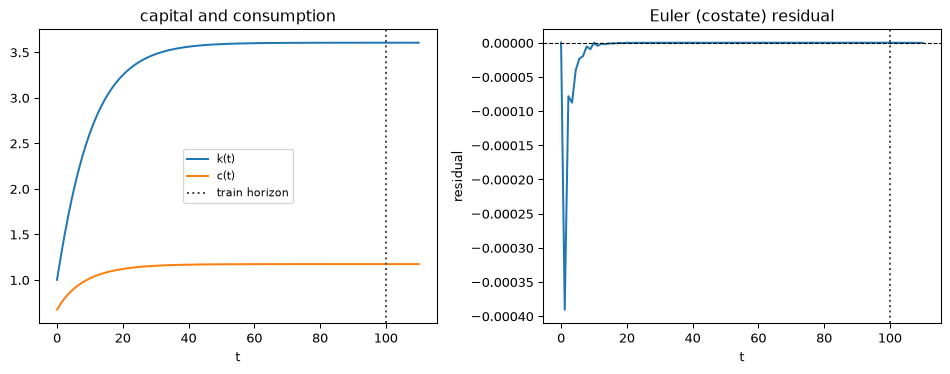

In [10]:
c_test = theta["c_0"] + K_tilde_test @ theta["alpha_c"]

fig, (ax_k, ax_r) = plt.subplots(1, 2, figsize=(10, 4))
ax_k.plot(t_test, k_test, "C0", label="k(t)")
ax_k.plot(t_test, c_test, "C1", label="c(t)")
ax_k.axvline(TRAIN_T, color="0.3", linestyle=":", label="train horizon")
ax_k.set(xlabel="t", title="capital and consumption")
ax_k.legend(fontsize=8)
ax_r.plot(t_test, euler_test, "C0")
ax_r.axhline(0.0, color="k", linestyle="--", linewidth=0.8)
ax_r.axvline(TRAIN_T, color="0.3", linestyle=":")
ax_r.set(xlabel="t", ylabel="residual", title="Euler (costate) residual")
fig.tight_layout()
plt.show()